In [15]:
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import numpy as np  
from mlguess.data.dataset import LmdbDataset
from sklearn.linear_model import LinearRegression
import json
import matplotlib.pyplot as plt
import tarfile
from io import BytesIO
from scipy.stats import gaussian_kde
np.random.seed(42)

In [3]:
outputs = np.load('/home/ihor/projects/MLGuessQC/mlguess/results/tmQMneutral_FPCmatch_filtered_charges/orbital_charges_epoch_23.npz')

In [4]:
outputs['ground_truth'].shape

(637437,)

/tmp/ipykernel_2915134/4097877709.py:13: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(x, y, s=10, alpha=0.1, cmap='viridis', label=f"MSE: {mse:.5f}, MAE: {mae:.4f}")


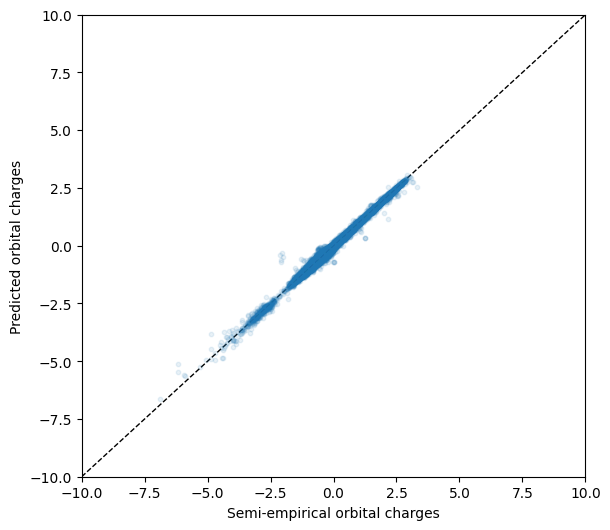

In [17]:
# Extract data from the results
x = outputs['ground_truth']#[:30000]
y = outputs['predictions']#[:30000]

mse = np.mean((x - y) ** 2)
mae = np.mean(np.abs(x - y))

# xy = np.vstack([x, y])
# z = gaussian_kde(xy)(xy)

# Create the scatter plot
plt.figure(figsize=(6.5, 6))
plt.scatter(x, y, s=10, alpha=0.1, cmap='viridis', label=f"MSE: {mse:.5f}, MAE: {mae:.4f}")
plt.plot([-10, 10], [-10, 10], 'k--', linewidth=1, zorder=0)
plt.xlim(-10, 10)
plt.ylim(-10, 10)
#plt.colorbar(label='Density')
plt.xlabel('Semi-empirical orbital charges')
plt.ylabel('Predicted orbital charges')
#plt.legend()
plt.show()

In [5]:
def process_npz_file(file_path):
    """
    Process a single NPZ file and extract the relevant data.
    """
    data = np.load(file_path)
    orbital_map = np.load("/home/ihor/projects/MLGuessQC/dxtb_experiments/dxtb_orbital_map.npz")
    print(data)
    
    mol_numbers = []
    mol_positions = []
    mol_charges_targer = []
    mol_charges_pred = []
    n_atom = data["n_atom"]
    flat_numbers = data["atom_types"]
    flat_positions = data["coords"]
    flat_charges_targer = data["ground_truth"]
    flat_charges_pred = data["predictions"]
    start_atom_idx = 0
    start_orbital_idx = 0
    for i in range(len(n_atom)):
        n = n_atom[i]
        mol_numbers.append(flat_numbers[start_atom_idx:start_atom_idx + n])
        n_orbitals = 0
        for atom in flat_numbers[start_atom_idx:start_atom_idx + n]:
            n_orbitals += orbital_map[str(atom)]
 
        mol_charges_pred.append(flat_charges_pred[start_orbital_idx:start_orbital_idx + n_orbitals])
        mol_charges_targer.append(flat_charges_targer[start_orbital_idx:start_orbital_idx + n_orbitals])
        mol_positions.append(flat_positions[start_atom_idx:start_atom_idx + n])
        start_atom_idx += n
        start_orbital_idx += n_orbitals
    
    return mol_numbers, mol_positions, mol_charges_targer, mol_charges_pred

In [20]:
mol_numbers, mol_positions, mol_charges_target, mol_charges_pred = process_npz_file('/home/ihor/projects/MLGuessQC/mlguess/results/tmQMneutral_FPCmatch_filtered_charges/orbital_charges_epoch_23.npz')

NpzFile '/home/ihor/projects/MLGuessQC/mlguess/results/tmQMneutral_FPCmatch_filtered_charges/orbital_charges_epoch_23.npz' with keys: n_atom, atom_types, coords, ground_truth, predictions


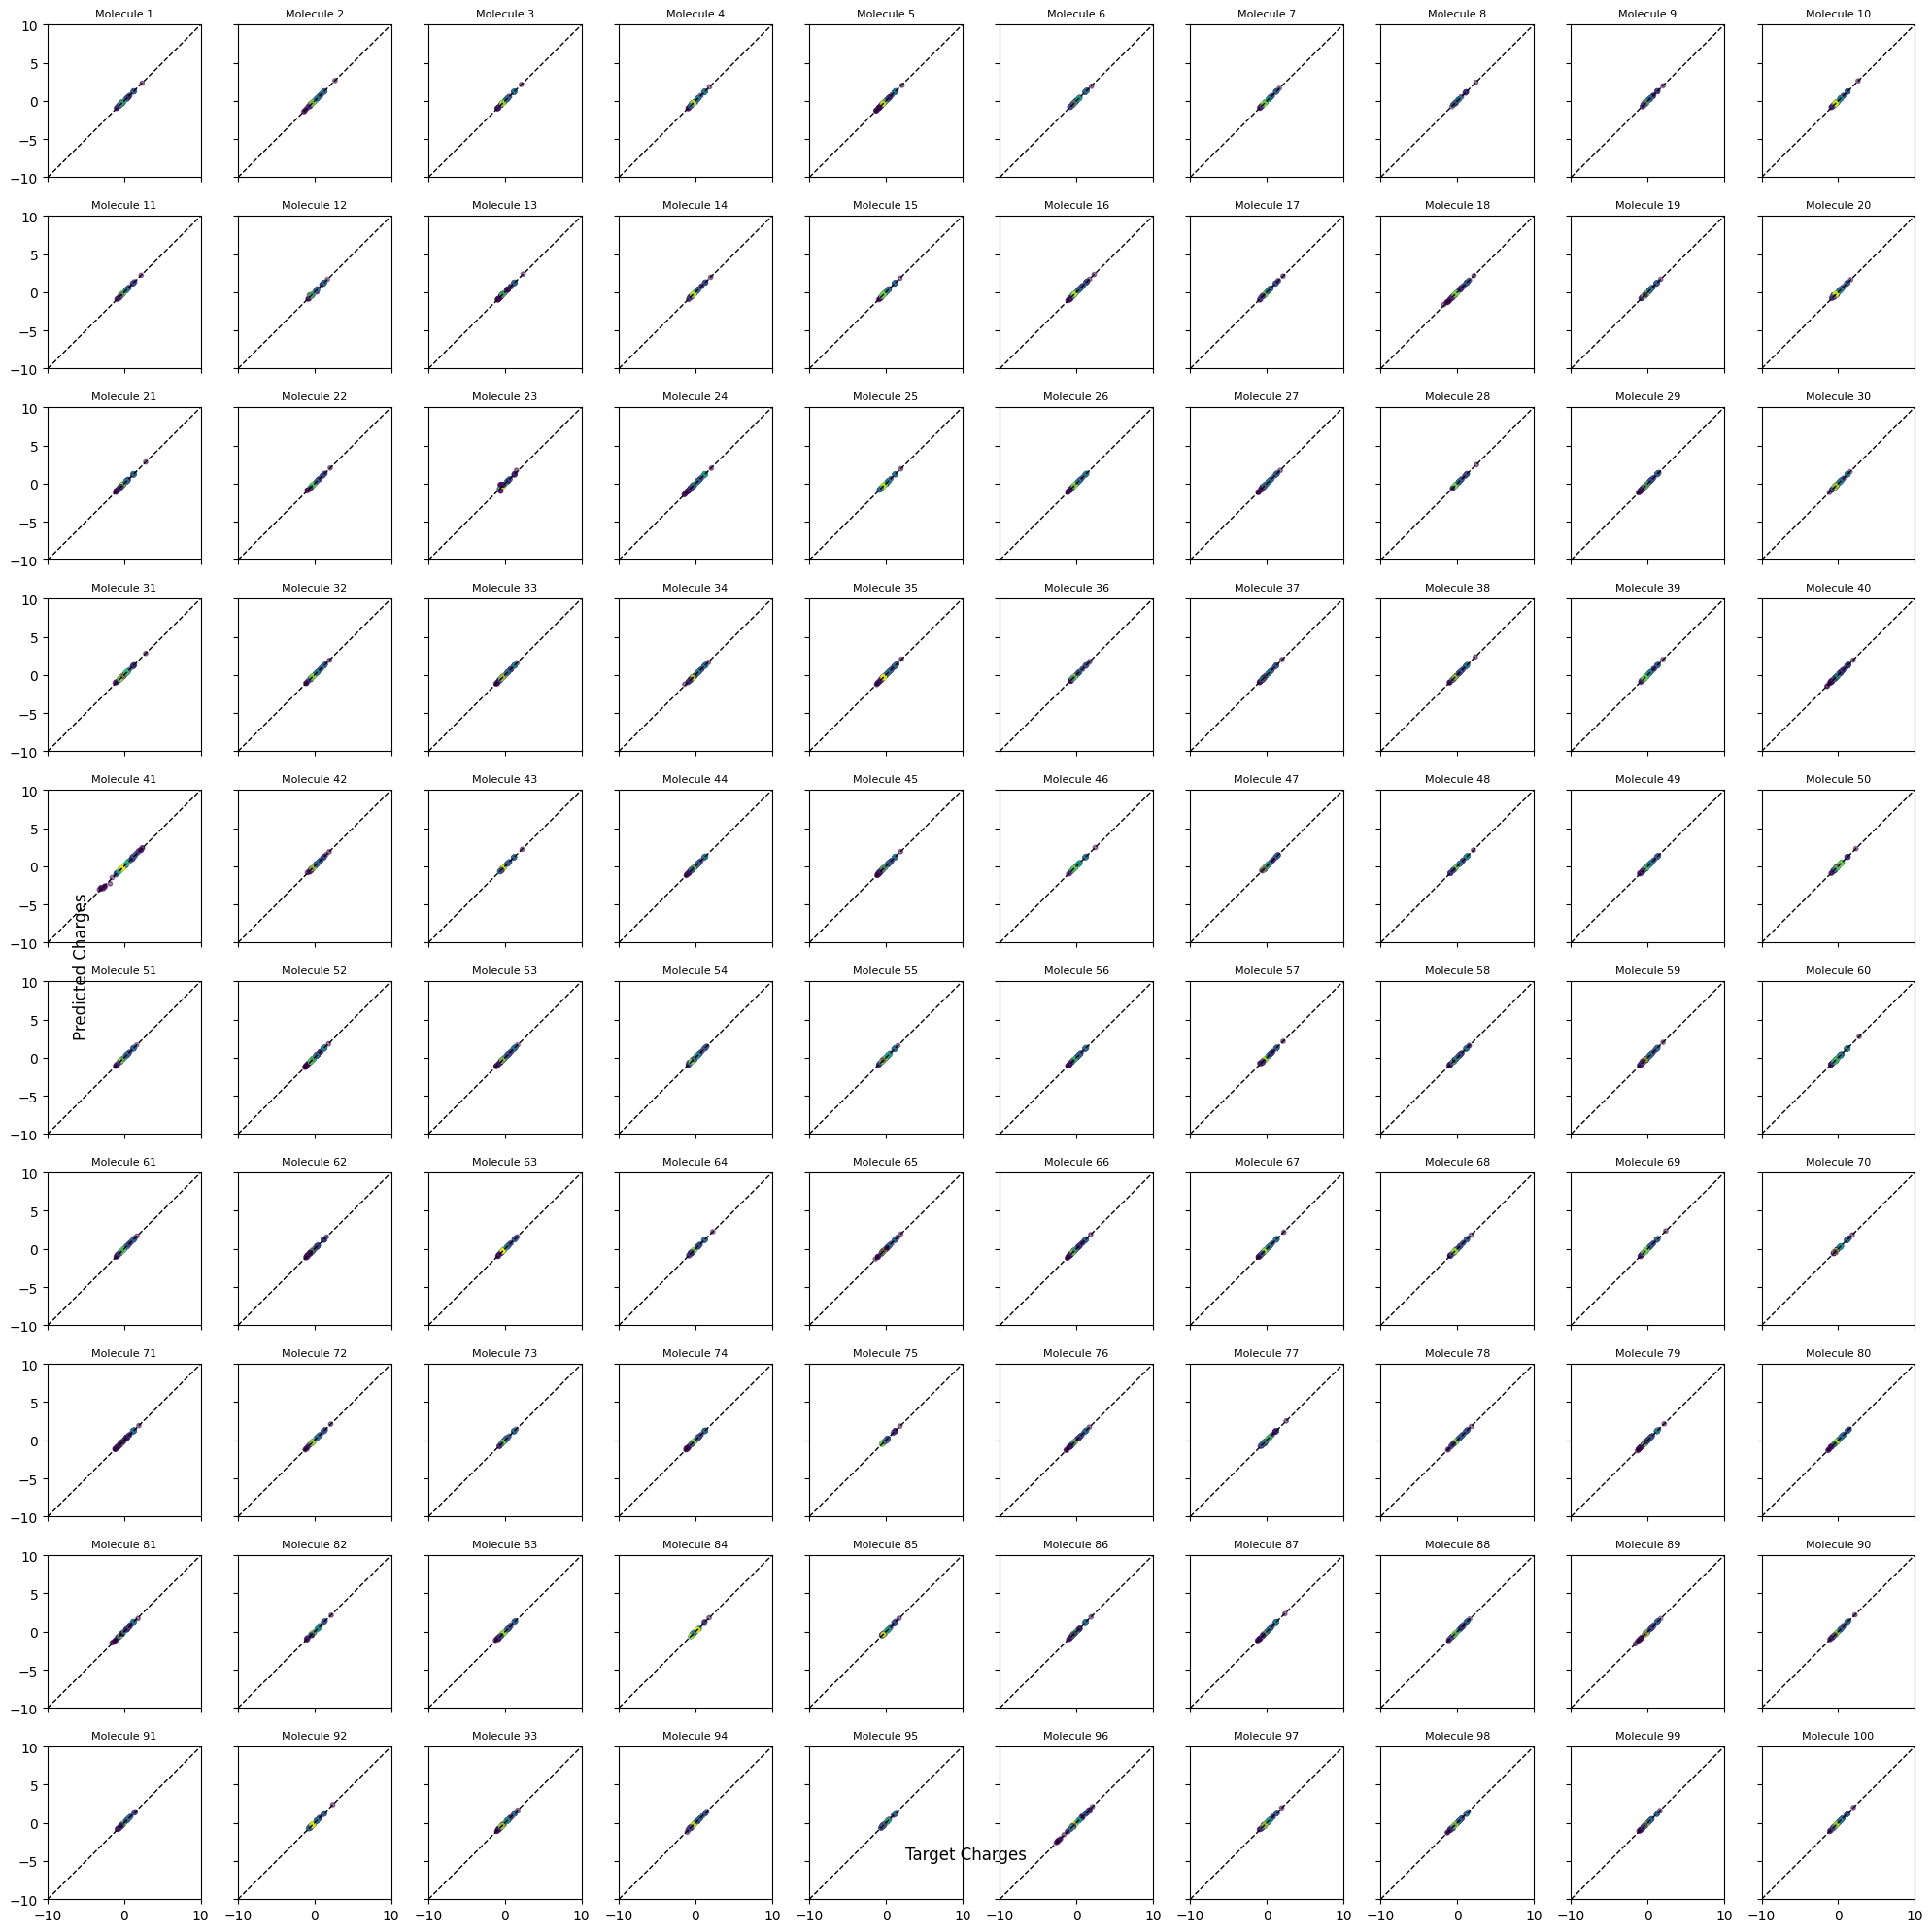

In [21]:
# Create a 10x10 grid of subplots
fig, axes = plt.subplots(nrows=10, ncols=10, figsize=(20, 20), sharex=True, sharey=True)
axes = axes.flatten()

# Plot each molecule's data in a separate subplot
for idx, (charges_target, charges_pred) in enumerate(zip(mol_charges_target, mol_charges_pred)):
    if idx >= 100:  # Limit to 100 subplots
        break
    ax = axes[idx]
    xy_filtered = np.vstack([charges_target, charges_pred])
    z_filtered = gaussian_kde(xy_filtered)(xy_filtered)
    ax.scatter(charges_target, charges_pred, s=10, alpha=0.5, c=z_filtered)
    ax.plot([-10, 10], [-10, 10], 'k--', linewidth=1)  # Diagonal line
    ax.set_title(f'Molecule {idx + 1}', fontsize=8)
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)

# Remove unused subplots
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

# Add common labels
fig.text(0.5, 0.04, 'Target Charges', ha='center', fontsize=12)
fig.text(0.04, 0.5, 'Predicted Charges', va='center', rotation='vertical', fontsize=12)

plt.tight_layout()
plt.show()

In [22]:
mol_mse = [np.mean((target - pred) ** 2) for target, pred in zip(mol_charges_target, mol_charges_pred)]
mol_n_atoms = [len(mol) for mol in mol_numbers]

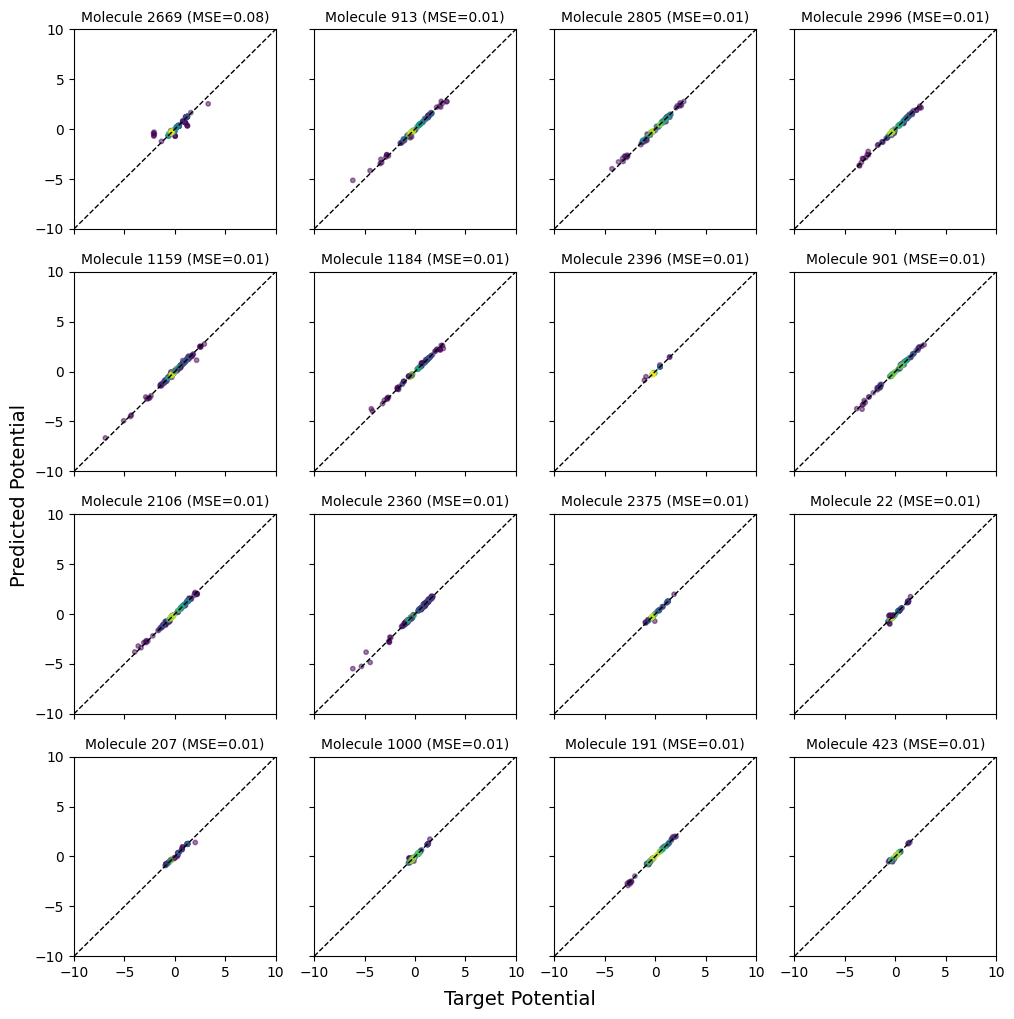

In [26]:
# Find indices of molecules with highest mol_mse (e.g., top 16)
top_n = 16
top_indices = np.argsort(mol_mse)[-top_n:][::-1]

fig, axes = plt.subplots(4, 4, figsize=(10, 10), sharex=True, sharey=True)
axes = axes.flatten()

for i, idx in enumerate(top_indices):
    charges_target = mol_charges_target[idx]
    charges_pred = mol_charges_pred[idx]
    xy_filtered = np.vstack([charges_target, charges_pred])
    z_filtered = gaussian_kde(xy_filtered)(xy_filtered)
    ax = axes[i]
    ax.scatter(charges_target, charges_pred, s=10, alpha=0.5, c=z_filtered)
    ax.plot([-10, 10], [-10, 10], 'k--', linewidth=1)
    ax.set_title(f'Molecule {idx} (MSE={mol_mse[idx]:.2f})', fontsize=10)
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.text(0.5, -0.01, 'Target Potential', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'Predicted Potential', va='center', rotation='vertical', fontsize=14)
plt.tight_layout()
plt.show()

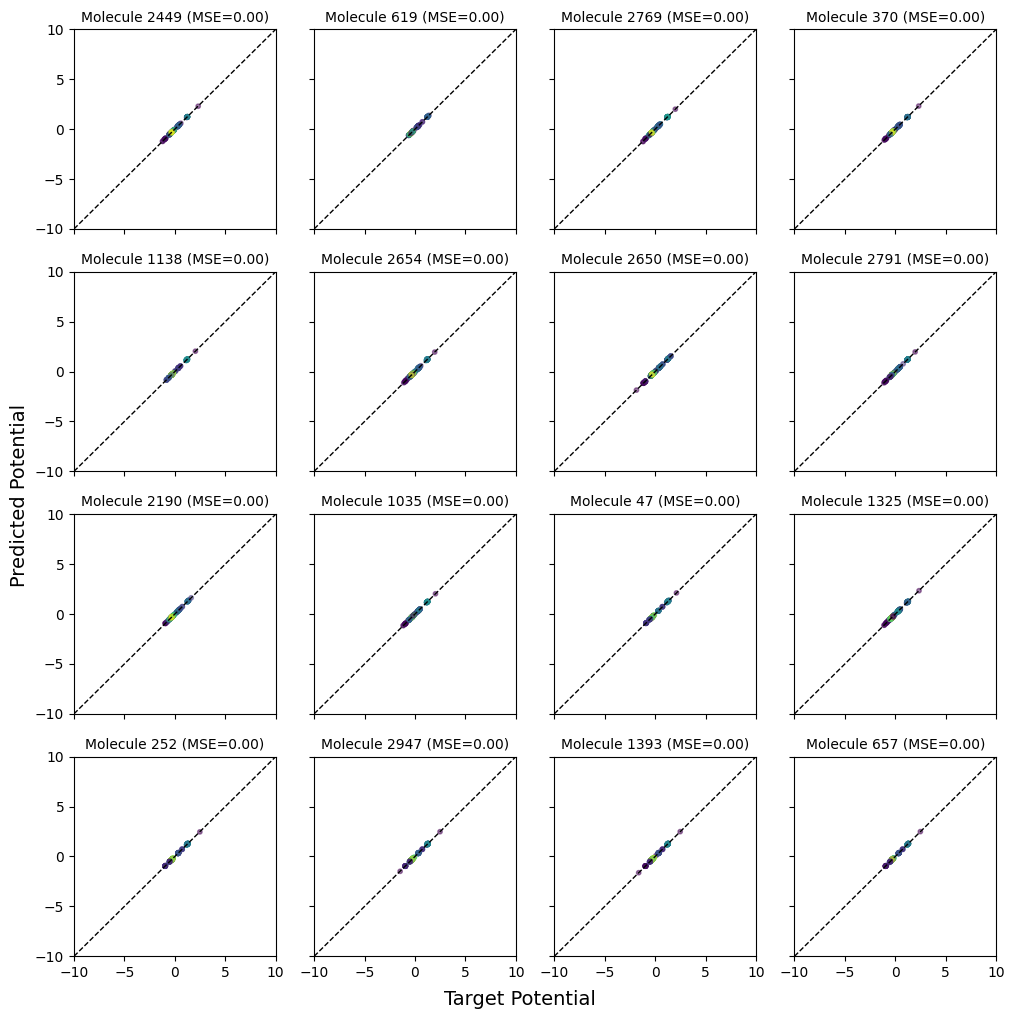

In [27]:
# Find indices of molecules with lowest mol_mse (e.g., top 16)
top_n = 16
top_indices = np.argsort(mol_mse)[:top_n][::-1]

fig, axes = plt.subplots(4, 4, figsize=(10, 10), sharex=True, sharey=True)
axes = axes.flatten()

for i, idx in enumerate(top_indices):
    charges_target = mol_charges_target[idx]
    charges_pred = mol_charges_pred[idx]
    xy_filtered = np.vstack([charges_target, charges_pred])
    z_filtered = gaussian_kde(xy_filtered)(xy_filtered)
    ax = axes[i]
    ax.scatter(charges_target, charges_pred, s=10, alpha=0.5, c=z_filtered)
    ax.plot([-10, 10], [-10, 10], 'k--', linewidth=1)
    ax.set_title(f'Molecule {idx} (MSE={mol_mse[idx]:.2f})', fontsize=10)
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.text(0.5, -0.01, 'Target Potential', ha='center', fontsize=14)
fig.text(-0.01, 0.5, 'Predicted Potential', va='center', rotation='vertical', fontsize=14)
plt.tight_layout()
plt.show()

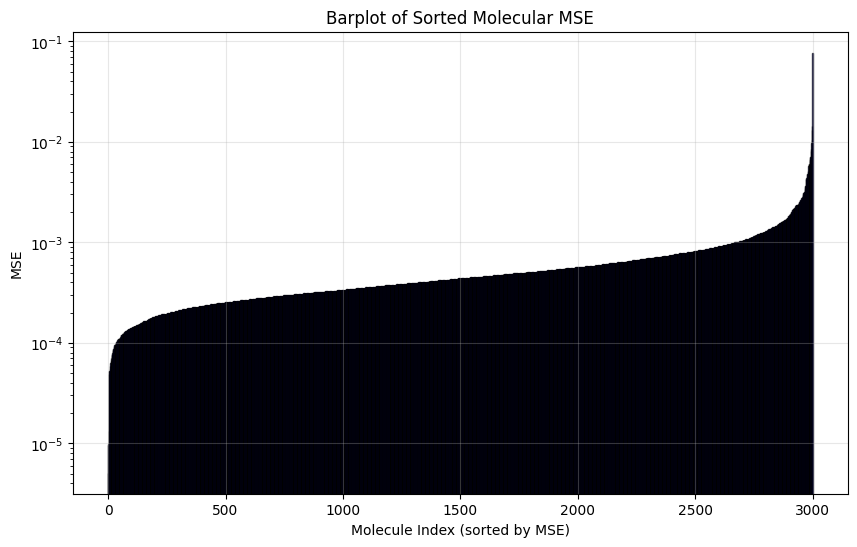

In [28]:
# Plot barplot of sorted mol_mse
plt.figure(figsize=(10, 6))
plt.bar(range(len(mol_mse)), sorted(mol_mse), color='blue', alpha=0.7, edgecolor='black')
plt.xlabel('Molecule Index (sorted by MSE)')
plt.ylabel('MSE')
plt.title('Barplot of Sorted Molecular MSE')
plt.grid(alpha=0.3)
plt.yscale('log')  # Use logarithmic scale for better visibility
plt.show()

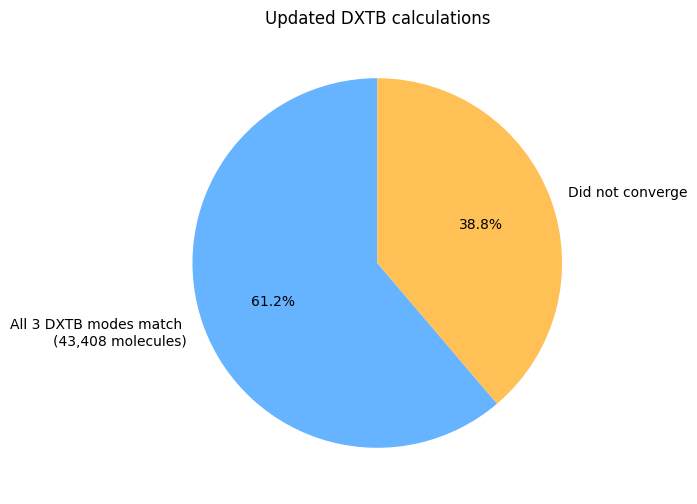

In [36]:
# Pie chart with two components
sizes = [43408, 70900 - 43408]
labels = ['All 3 DXTB modes match \n(43,408 molecules)', 'Did not converge']
colors = ['#66b3ff', "#FFC155"]

plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Updated DXTB calculations')
plt.show()

In [50]:
results_benchmark = np.load('/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_SCF_MODE_FULL.npz')
results_benchmark

NpzFile '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_SCF_MODE_FULL.npz' with keys: n_scf_iter_default, n_scf_iter_ml_guess, calc_time_default, calc_time_ml_guess, charge_mse...

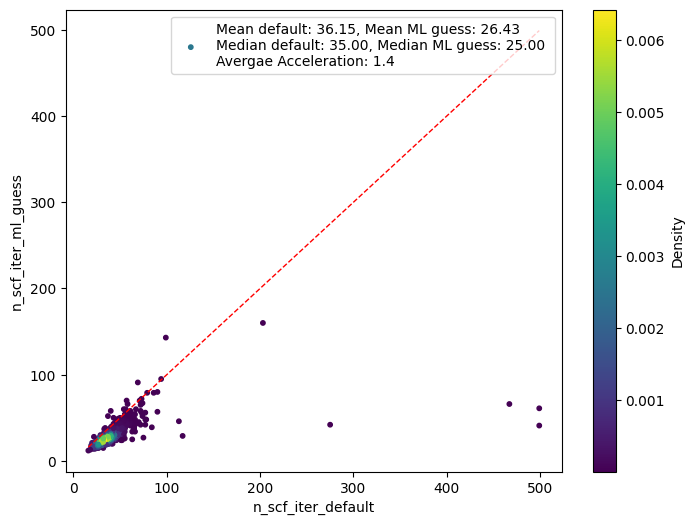

In [51]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

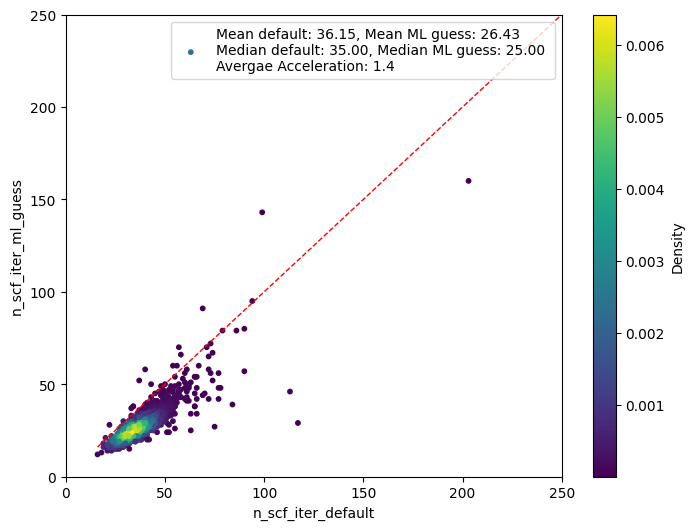

In [52]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.xlim(0, 250)
plt.ylim(0, 250)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

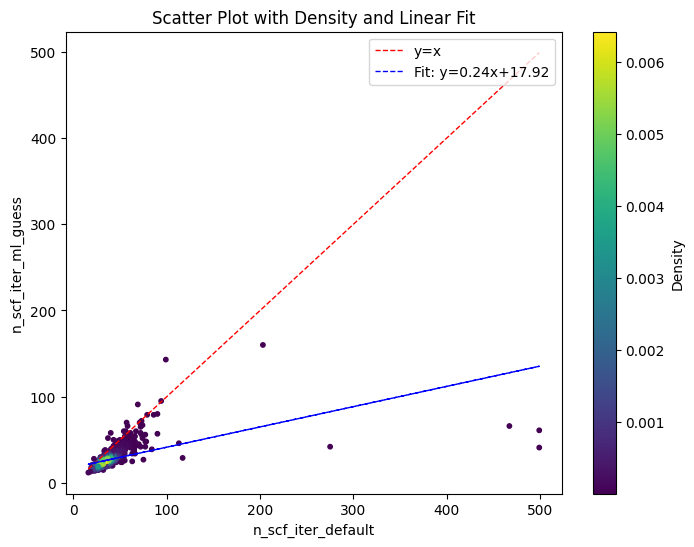

In [53]:
from sklearn.linear_model import LinearRegression

# Flatten arrays for fitting
x_flat = n_scf_iter_default.flatten().reshape(-1, 1)
y_flat = n_scf_iter_ml_guess.flatten()

# Fit linear regression
reg = LinearRegression().fit(x_flat, y_flat)
y_pred = reg.predict(x_flat)

# Scatter plot with density
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2, label='y=x')
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis')
plt.plot(x_flat, y_pred, "b--", linewidth=1, label=f'Fit: y={reg.coef_[0]:.2f}x+{reg.intercept_:.2f}')
#plt.xlim(0, 250)
#plt.ylim(0, 250)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
plt.title('Scatter Plot with Density and Linear Fit')
plt.show()

# SCF mode IMPLICIT

In [54]:
results_benchmark = np.load('/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_SCF_MODE_IMPLICIT.npz')
results_benchmark

NpzFile '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_SCF_MODE_IMPLICIT.npz' with keys: n_scf_iter_default, n_scf_iter_ml_guess, calc_time_default, calc_time_ml_guess, charge_mse...

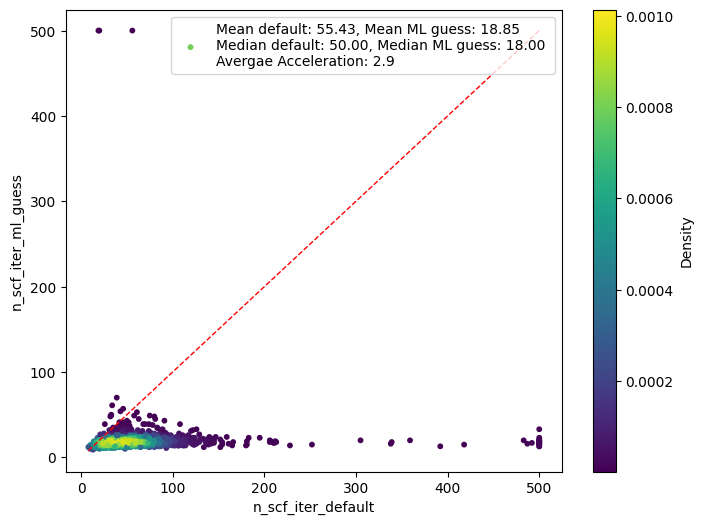

In [55]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

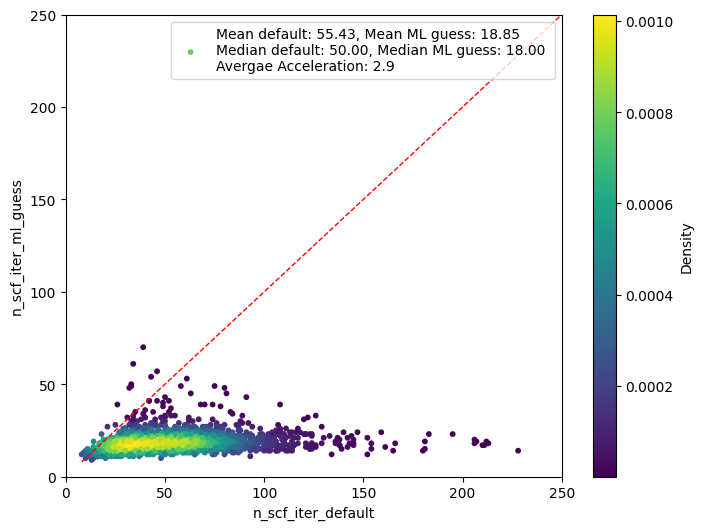

In [56]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.xlim(0, 250)
plt.ylim(0, 250)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

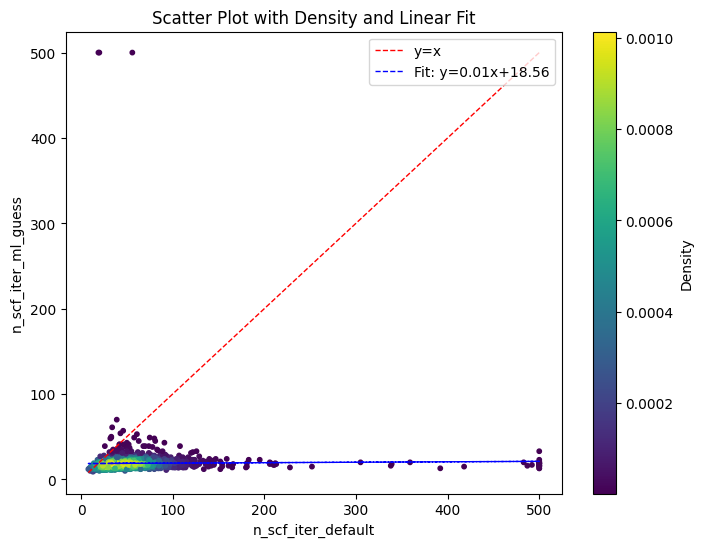

In [57]:
from sklearn.linear_model import LinearRegression

# Flatten arrays for fitting
x_flat = n_scf_iter_default.flatten().reshape(-1, 1)
y_flat = n_scf_iter_ml_guess.flatten()

# Fit linear regression
reg = LinearRegression().fit(x_flat, y_flat)
y_pred = reg.predict(x_flat)

# Scatter plot with density
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2, label='y=x')
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis')
plt.plot(x_flat, y_pred, "b--", linewidth=1, label=f'Fit: y={reg.coef_[0]:.2f}x+{reg.intercept_:.2f}')
#plt.xlim(0, 250)
#plt.ylim(0, 250)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
plt.title('Scatter Plot with Density and Linear Fit')
plt.show()

# SCF mode defFull mlIMPLICIT

In [16]:
results_benchmark = np.load('/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_SCF_MODE_defFULL_mlIMPLICIT.npz')
results_benchmark

NpzFile '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_SCF_MODE_defFULL_mlIMPLICIT.npz' with keys: n_scf_iter_default, n_scf_iter_ml_guess, calc_time_default, calc_time_ml_guess, charge_mse...

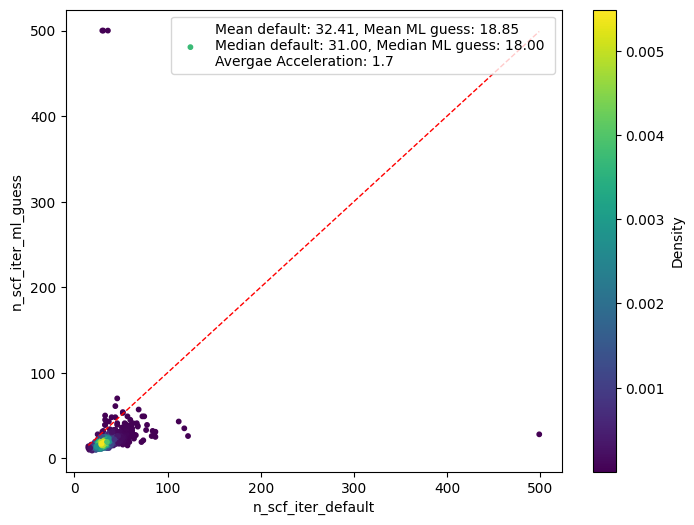

In [17]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

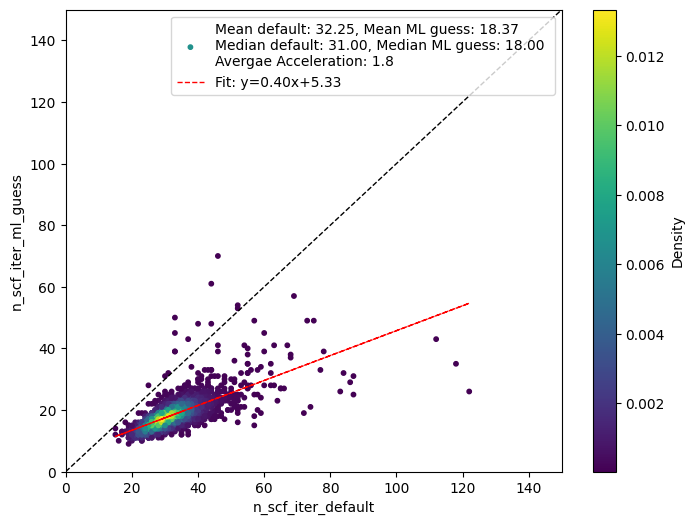

In [18]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_iter_default = n_scf_iter_default[(results_benchmark['n_scf_iter_default'] <= 200) & (results_benchmark['n_scf_iter_ml_guess'] <= 200)]
n_scf_iter_ml_guess = n_scf_iter_ml_guess[(results_benchmark['n_scf_iter_default'] <= 200) & (results_benchmark['n_scf_iter_ml_guess'] <= 200)]

# Flatten arrays for fitting
x_flat = n_scf_iter_default.flatten().reshape(-1, 1)
y_flat = n_scf_iter_ml_guess.flatten()

# Fit linear regression
reg = LinearRegression().fit(x_flat, y_flat)
y_pred = reg.predict(x_flat)

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([0, 150], 
         [0, 150], 
         'k--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.plot(x_flat, y_pred, "r--", linewidth=1, label=f'Fit: y={reg.coef_[0]:.2f}x+{reg.intercept_:.2f}')
plt.xlim(0, 150)
plt.ylim(0, 150)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

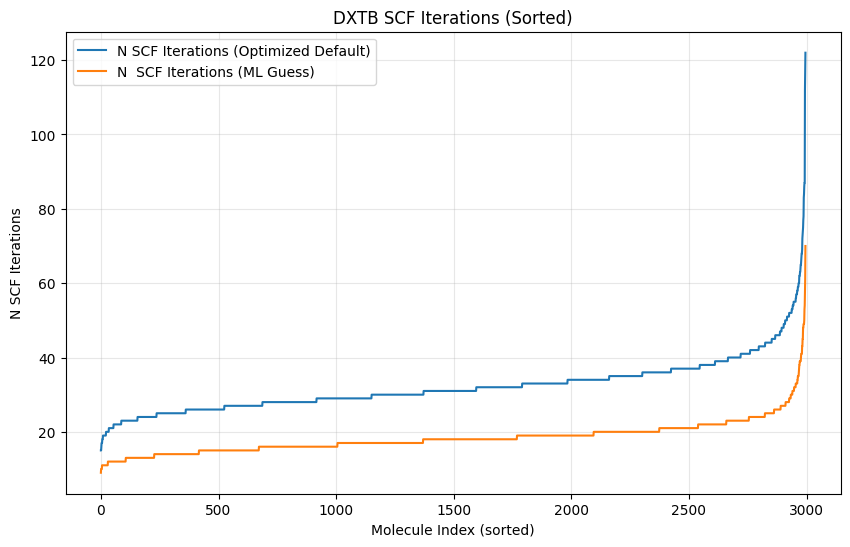

In [27]:
# Plot sorted cumulative sums of n_scf_iter_default and n_scf_iter_ml_guess
plt.figure(figsize=(10, 6))
default_sorted = np.sort(n_scf_iter_default)
ml_guess_sorted = np.sort(n_scf_iter_ml_guess)
cum_default = np.cumsum(default_sorted)
cum_ml_guess = np.cumsum(ml_guess_sorted)

plt.plot(default_sorted, label='N SCF Iterations (Optimized Default)')
plt.plot(ml_guess_sorted, label='N  SCF Iterations (ML Guess)')
plt.xlabel('Molecule Index (sorted)')
plt.ylabel('N SCF Iterations')
plt.title('DXTB SCF Iterations (Sorted)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
ml_guess_sorted

array([ 9, 10, 10, ..., 57, 61, 70])

In [10]:
for key in results_benchmark.keys():
    print(f"{key}")

n_scf_iter_default
n_scf_iter_ml_guess
calc_time_default
calc_time_ml_guess
charge_mse
charge_mae


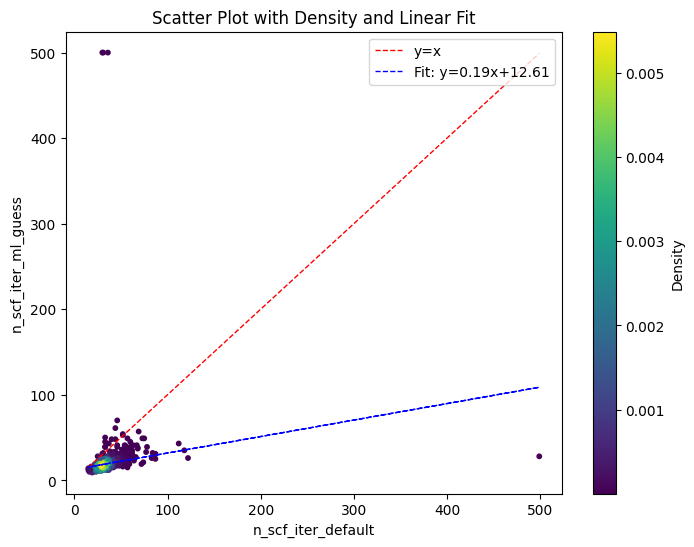

In [67]:
from sklearn.linear_model import LinearRegression

# Flatten arrays for fitting
x_flat = n_scf_iter_default.flatten().reshape(-1, 1)
y_flat = n_scf_iter_ml_guess.flatten()

# Fit linear regression
reg = LinearRegression().fit(x_flat, y_flat)
y_pred = reg.predict(x_flat)

# Scatter plot with density
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2, label='y=x')
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis')
plt.plot(x_flat, y_pred, "b--", linewidth=1, label=f'Fit: y={reg.coef_[0]:.2f}x+{reg.intercept_:.2f}')
#plt.xlim(0, 250)
#plt.ylim(0, 250)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
plt.title('Scatter Plot with Density and Linear Fit')
plt.show()

# SCF mode defFullcharge mlIMPLICITpotential

In [5]:
results_benchmark = np.load('/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_SCF_MODE_defFULLcharge_mlIMPLICITpotential.npz')
results_benchmark

NpzFile '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_SCF_MODE_defFULLcharge_mlIMPLICITpotential.npz' with keys: n_scf_iter_default, n_scf_iter_ml_guess, calc_time_default, calc_time_ml_guess, charge_mse...

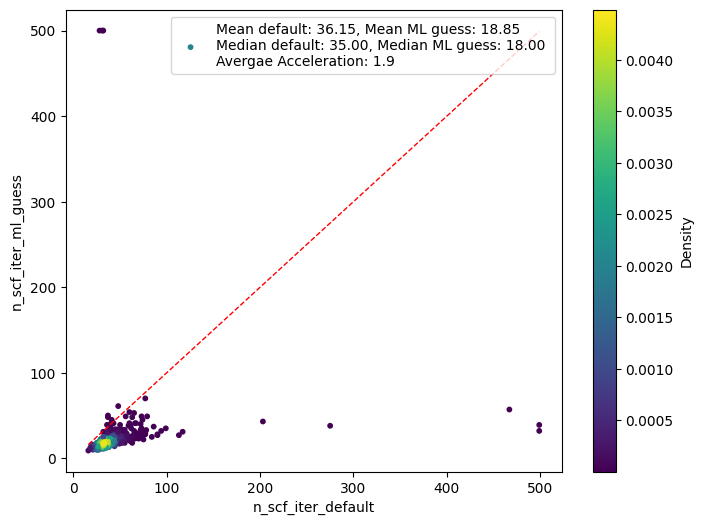

In [6]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

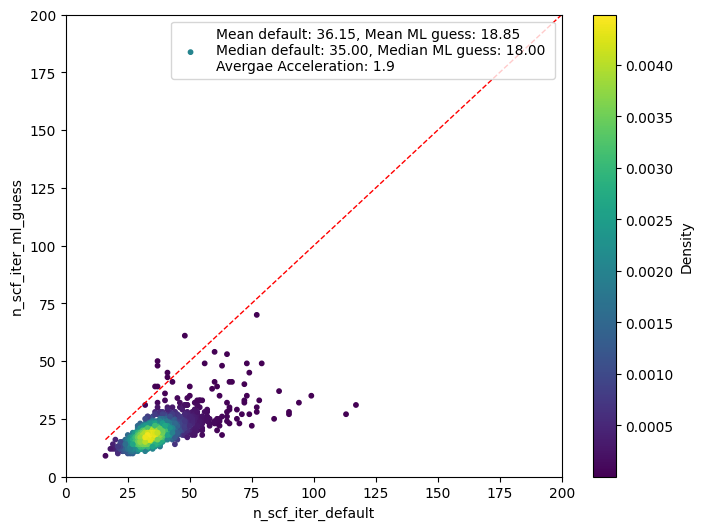

In [7]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.xlim(0, 200)
plt.ylim(0, 200)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

In [8]:
n_scf_iter_default[n_scf_iter_default > 200]

array([467, 203, 499, 499, 275])

In [9]:
n_scf_iter_ml_guess[n_scf_iter_ml_guess > 200]

array([500, 500, 500])

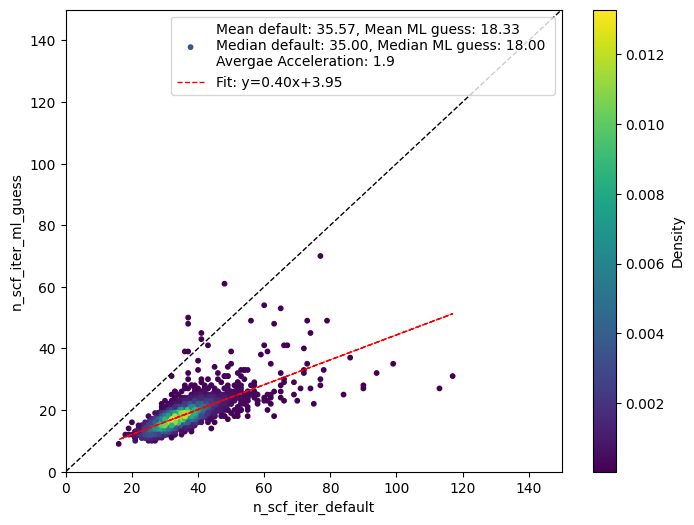

In [22]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_iter_default = n_scf_iter_default[(results_benchmark['n_scf_iter_default'] <= 200) & (results_benchmark['n_scf_iter_ml_guess'] <= 200)]
n_scf_iter_ml_guess = n_scf_iter_ml_guess[(results_benchmark['n_scf_iter_default'] <= 200) & (results_benchmark['n_scf_iter_ml_guess'] <= 200)]

# Flatten arrays for fitting
x_flat = n_scf_iter_default.flatten().reshape(-1, 1)
y_flat = n_scf_iter_ml_guess.flatten()

# Fit linear regression
reg = LinearRegression().fit(x_flat, y_flat)
y_pred = reg.predict(x_flat)

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([0, 150], 
         [0, 150], 
         'k--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.plot(x_flat, y_pred, "r--", linewidth=1, label=f'Fit: y={reg.coef_[0]:.2f}x+{reg.intercept_:.2f}')
plt.xlim(0, 150)
plt.ylim(0, 150)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

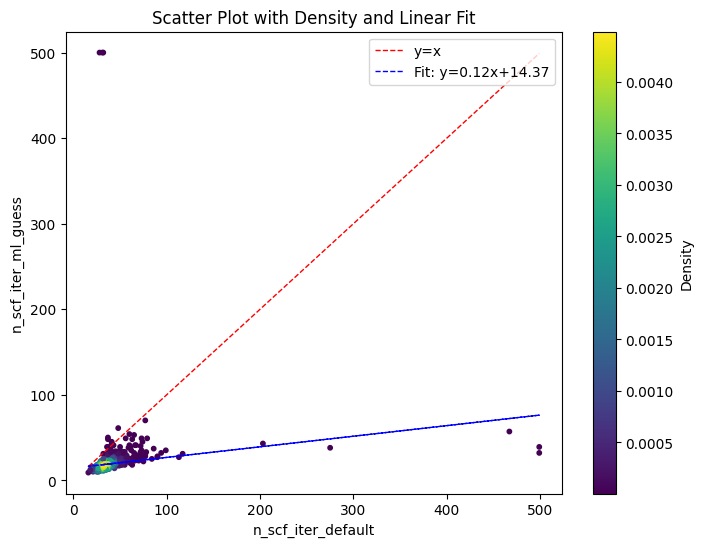

In [ ]:
# Flatten arrays for fitting
x_flat = n_scf_iter_default.flatten().reshape(-1, 1)
y_flat = n_scf_iter_ml_guess.flatten()

# Fit linear regression
reg = LinearRegression().fit(x_flat, y_flat)
y_pred = reg.predict(x_flat)

# Scatter plot with density
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2, label='y=x')
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis')
plt.plot(x_flat, y_pred, "b--", linewidth=1, label=f'Fit: y={reg.coef_[0]:.2f}x+{reg.intercept_:.2f}')
#plt.xlim(0, 250)
#plt.ylim(0, 250)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
plt.title('Scatter Plot with Density and Linear Fit')
plt.show()

# SCF mode defIMPLICITcharge mlIMPLICITpotential

In [75]:
results_benchmark = np.load('/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_SCF_MODE_defIMPLICITcharge_mlIMPLICITpotential.npz')
results_benchmark

NpzFile '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_SCF_MODE_defIMPLICITcharge_mlIMPLICITpotential.npz' with keys: n_scf_iter_default, n_scf_iter_ml_guess, calc_time_default, calc_time_ml_guess, charge_mse...

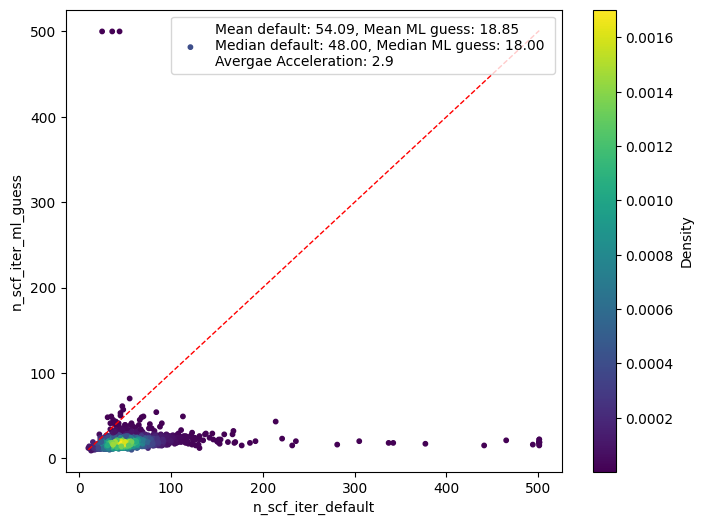

In [76]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

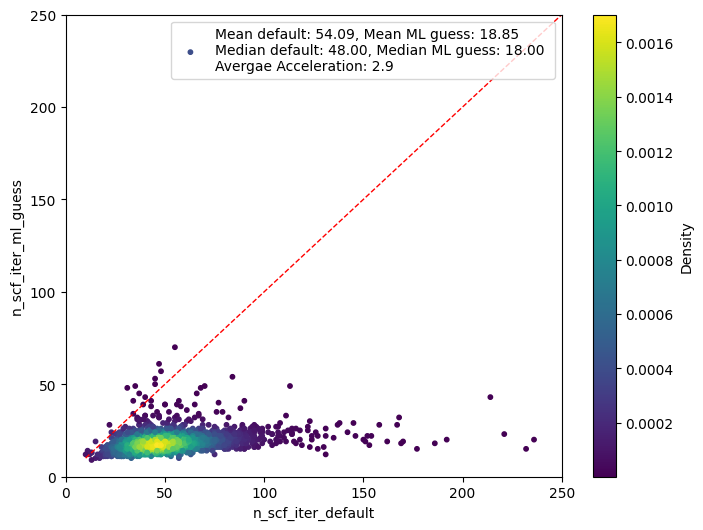

In [77]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.xlim(0, 250)
plt.ylim(0, 250)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

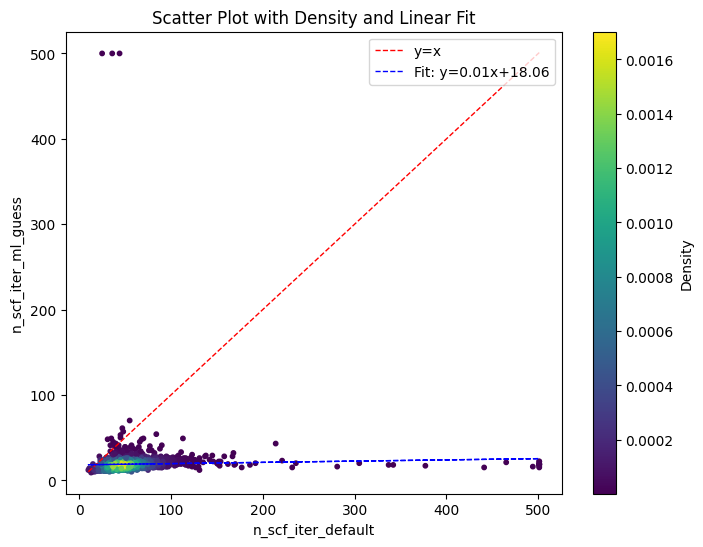

In [78]:
from sklearn.linear_model import LinearRegression

# Flatten arrays for fitting
x_flat = n_scf_iter_default.flatten().reshape(-1, 1)
y_flat = n_scf_iter_ml_guess.flatten()

# Fit linear regression
reg = LinearRegression().fit(x_flat, y_flat)
y_pred = reg.predict(x_flat)

# Scatter plot with density
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2, label='y=x')
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis')
plt.plot(x_flat, y_pred, "b--", linewidth=1, label=f'Fit: y={reg.coef_[0]:.2f}x+{reg.intercept_:.2f}')
#plt.xlim(0, 250)
#plt.ylim(0, 250)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
plt.title('Scatter Plot with Density and Linear Fit')
plt.show()

In [79]:
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

In [83]:
n_scf_iter_ml_guess[n_scf_iter_ml_guess.flatten() == 500]

array([[500],
       [500],
       [500]])

In [84]:
idx_500 = np.where(n_scf_iter_ml_guess.flatten() == 500)[0]
idx_500

array([ 290, 1081, 2562])

# Def_POTENTIAL_IMPLICIT_NON_PURE_ML_CHARGE_IMPLICIT_NON_PURE

In [28]:
results_benchmark = np.load('/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_Def_POTENTIAL_IMPLICIT_NON_PURE_ML_CHARGE_IMPLICIT_NON_PURE.npz')
results_benchmark

NpzFile '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/test_benchmark_charges_Def_POTENTIAL_IMPLICIT_NON_PURE_ML_CHARGE_IMPLICIT_NON_PURE.npz' with keys: n_scf_iter_default, n_scf_iter_ml_guess, calc_time_default, calc_time_ml_guess, charge_mse...

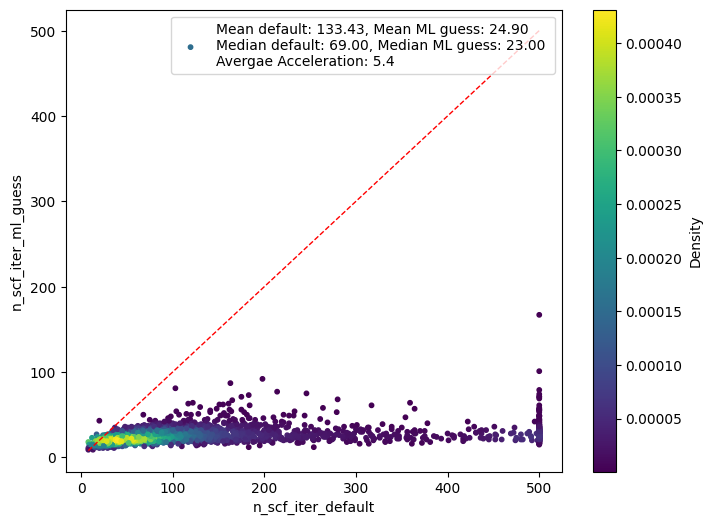

In [29]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

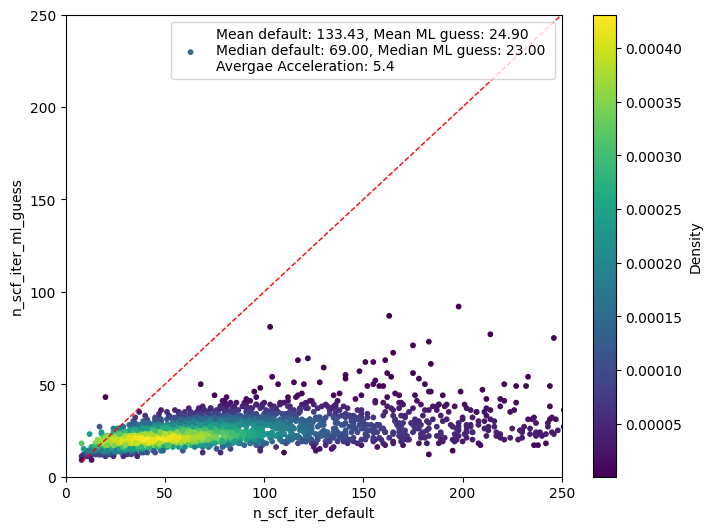

In [87]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([min(n_scf_iter_default), max(n_scf_iter_default)], 
         [min(n_scf_iter_default), max(n_scf_iter_default)], 
         'r--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.xlim(0, 250)
plt.ylim(0, 250)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

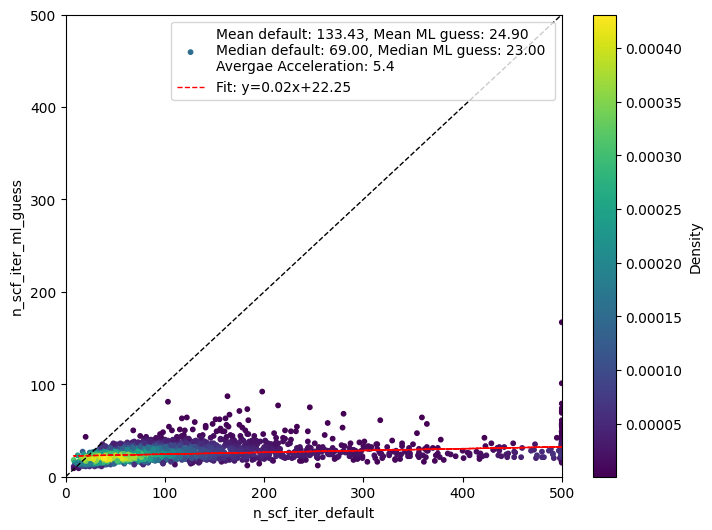

In [38]:
n_scf_iter_default = results_benchmark['n_scf_iter_default']
n_scf_iter_ml_guess = results_benchmark['n_scf_iter_ml_guess']

#n_scf_iter_default = n_scf_iter_default[(results_benchmark['n_scf_iter_default'] <= 500) & (results_benchmark['n_scf_iter_ml_guess'] <= 500)]
#n_scf_iter_ml_guess = n_scf_iter_ml_guess[(results_benchmark['n_scf_iter_default'] <= 500) & (results_benchmark['n_scf_iter_ml_guess'] <= 500)]

# Flatten arrays for fitting
x_flat = n_scf_iter_default.flatten().reshape(-1, 1)
y_flat = n_scf_iter_ml_guess.flatten()

# Fit linear regression
reg = LinearRegression().fit(x_flat, y_flat)
y_pred = reg.predict(x_flat)

n_scf_default_mean = np.mean(n_scf_iter_default)
n_scf_ml_guess_mean = np.mean(n_scf_iter_ml_guess)
n_scf_default_median = np.median(n_scf_iter_default)
n_scf_ml_guess_median = np.median(n_scf_iter_ml_guess)


xy = np.vstack([n_scf_iter_default.flatten(), n_scf_iter_ml_guess.flatten()])
z = gaussian_kde(xy)(xy)

average_acc = n_scf_default_mean/n_scf_ml_guess_mean

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.plot([0, 500], 
         [0, 500], 
         'k--', linewidth=1, zorder=2)
plt.scatter(n_scf_iter_default, n_scf_iter_ml_guess, c=z, s=10, cmap='viridis', 
            label="Mean default: {:.2f}, Mean ML guess: {:.2f} \nMedian default: {:.2f}, Median ML guess: {:.2f} \nAvergae Acceleration: {:.1f}".format(n_scf_default_mean, n_scf_ml_guess_mean, n_scf_default_median, n_scf_ml_guess_median, average_acc))
plt.plot(x_flat, y_pred, "r--", linewidth=1, label=f'Fit: y={reg.coef_[0]:.2f}x+{reg.intercept_:.2f}')
plt.xlim(0, 500)
plt.ylim(0, 500)
plt.legend(loc='upper right', fontsize=10)
plt.colorbar(label='Density')
plt.xlabel('n_scf_iter_default')
plt.ylabel('n_scf_iter_ml_guess')
#plt.title('Scatter Plot with Density')
plt.show()

In [40]:
len(results_benchmark['n_scf_iter_default'][results_benchmark['n_scf_iter_default'] >= 499])

314

In [41]:
len(results_benchmark['n_scf_iter_ml_guess'][results_benchmark['n_scf_iter_ml_guess'] >= 499])

0

In [42]:
max(n_scf_iter_ml_guess)

array([167])

# QM9 predictions

In [3]:
outputs_qm9 = np.load('/home/ihor/projects/MLGuessQC/datasets/qm9_dxtb_converged/test_out.npz')

In [4]:
outputs_qm9

NpzFile '/home/ihor/projects/MLGuessQC/datasets/qm9_dxtb_converged/test_out.npz' with keys: n_atom, atom_types, coords, ground_truth, predictions...

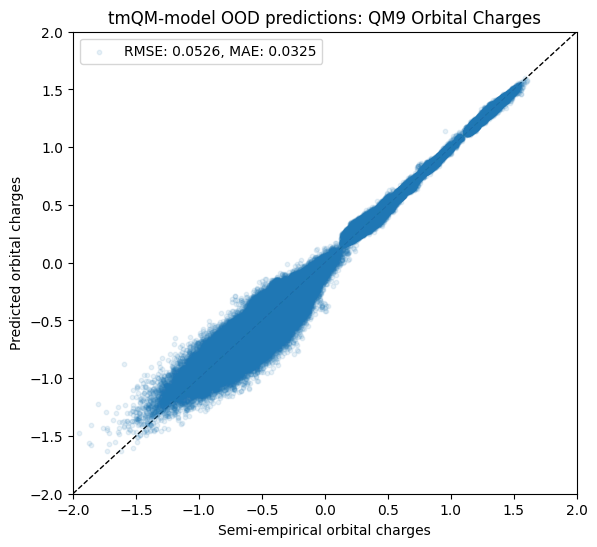

In [5]:
# Extract data from the results
x = outputs_qm9['ground_truth']#[:30000]
y = outputs_qm9['predictions']#[:30000]

mse = np.mean((x - y) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(x - y))

# xy = np.vstack([x, y])
# z = gaussian_kde(xy)(xy)

# Create the scatter plot
plt.figure(figsize=(6.5, 6))
plt.scatter(x, y, s=10, alpha=0.1, label=f"RMSE: {rmse:.4f}, MAE: {mae:.4f}")
plt.plot([-2, 2], [-2, 2], 'k--', linewidth=1, zorder=0)
plt.xlim(-2, 2)
plt.ylim(-2, 2)
#plt.colorbar(label='Density')
plt.title('tmQM-model OOD predictions: QM9 Orbital Charges')
plt.xlabel('Semi-empirical orbital charges')
plt.ylabel('Predicted orbital charges')
plt.legend()
plt.show()

In [50]:
len(outputs_qm9['ground_truth'])

803684

In [6]:
0.0525/0.0214

2.453271028037383

In [7]:
0.0325 / 0.0121

2.6859504132231407

# Error vs Acceleration

### Test set check

In [54]:
with open('/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/datasplits_overfit.json', 'r') as f:
    datasplits_overfit = json.load(f)
    
with open('/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/datasplits.json', 'r') as f:
    datasplits = json.load(f)



In [56]:
datasplits_overfit['test'] == datasplits['test']

True